In [7]:
import qiskit as q
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator  # Changed from 'Aer'
from qiskit.visualization import plot_histogram
from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister
%matplotlib inline

In [2]:
# Create a simple quantum circuit
# 1. Define the Quantum Register (3 qubits)
qr = QuantumRegister(3, name="q")

# 2. Define the Classical Register (3 bits)
cr = ClassicalRegister(3, name="c")

# 3. Build the circuit using both registers
qc = QuantumCircuit(qr, cr)

# unknown = 0, alice = 1, bob = 2
# entangle alice and bob
qc.h(qr[1])  # Hadamard gate on Alice's qubit
qc.cx(qr[1], qr[2])  # CNOT gate to entangle Alice and Bob

# uncertain state of the unknown qubit
qc.h(qr[0])  # Hadamard gate on the unknown qubit to

qc.cx(qr[0], qr[1]) # CNOT between unknown and Alice
qc.h(qr[0])

# measure the unknown qubit and alice bit
qc.measure(qr[0], cr[0])
qc.measure(qr[1], cr[1])

# Measuring the state of Bob's qubit
with qc.if_test((cr, 0)):
    pass # Do nothing

# Case 2: if alice (1) and unknown (0) is 0,1 (Value 1)
with qc.if_test((cr, 1)):
    qc.z(qr[2])

# Case 3: if alice (1) and unknown (0) is 1,0 (Value 2)
with qc.if_test((cr, 2)):
    qc.x(qr[2])

# Case 4: if alice (1) and unknown (0) is 1,1 (Value 3)
with qc.if_test((cr, 3)):
    qc.x(qr[2])
    qc.z(qr[2])

qc.measure(qr[2], cr[2])  # Measure Bob's qubit into cr[2]

In [3]:
qc.draw() 

┌───┐          ┌───┐┌─┐                                               »
q_0: ┤ H ├───────■──┤ H ├┤M├───────────────────────────────────────────────»
     ├───┤     ┌─┴─┐└┬─┬┘└╥┘                                               »
q_1: ┤ H ├──■──┤ X ├─┤M├──╫────────────────────────────────────────────────»
     └───┘┌─┴─┐└───┘ └╥┘  ║  ┌────── ┌───┐ ───────┐ ┌────── ┌───┐ ───────┐ »
q_2: ─────┤ X ├───────╫───╫──┤ If-0  ┤ Z ├  End-0 ├─┤ If-0  ┤ X ├  End-0 ├─»
          └───┘       ║   ║  └──╥─── └───┘ ───────┘ └──╥─── └───┘ ───────┘ »
                      ║   ║  ┌──╨──┐                ┌──╨──┐                »
c: 3/═════════════════╩═══╩══╡ 0x1 ╞════════════════╡ 0x2 ╞════════════════»
                      1   0  └─────┘                └─────┘                »
«                                    
«q_0: ───────────────────────────────
«                                    
«q_1: ───────────────────────────────
«     ┌────── ┌───┐┌───┐ ───────┐ ┌─┐
«q_2: ┤ If-0  ┤ X ├┤ Z ├  End-0 ├─┤M├
«     └──╥─── └───┘└───┘ ───────┘ └╥┘
«     ┌──╨──┐                      ║ 
«c: 3/╡ 0x3 ╞══════════════════════╩═
«     └─────┘                      2

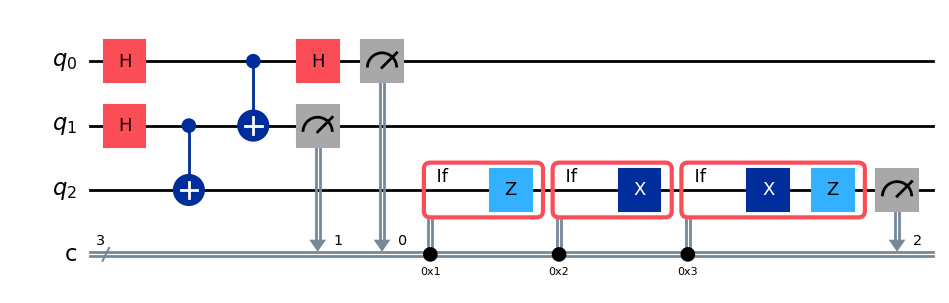

In [4]:
# use matplotlib to visualize the circuit
qc.draw(output='mpl')

{'000': 144, '001': 125, '111': 130, '011': 124, '010': 111, '100': 119, '110': 119, '101': 128}


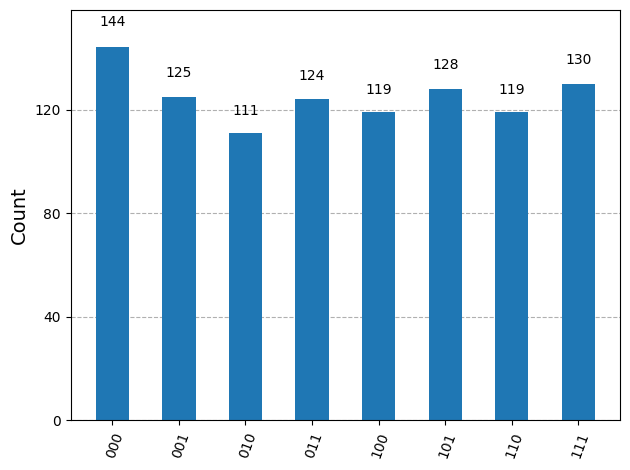

In [5]:
from qiskit import transpile
sim = AerSimulator()  # Changed from 'Aer.get_backend('qasm_simulator')'
compiled = transpile(qc, sim)
result = sim.run(compiled, shots=1000).result()
counts = result.get_counts(qc)
print(counts)
plot_histogram(counts)

In [1]:
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector

# Create circuit
qc = QuantumCircuit(1)

# List of steps (you can modify this)
steps = [
    ("H", lambda c: c.h(0)),
    ("Z", lambda c: c.z(0)),
    ("H", lambda c: c.h(0))
]

# Initial state
state = Statevector.from_label('0')

print("Step 0 (Initial):", state.data)

# Apply gates step-by-step
for i, (name, gate) in enumerate(steps, start=1):
    temp_circuit = QuantumCircuit(1)
    gate(temp_circuit)
    
    state = state.evolve(temp_circuit)
    
    print(f"Step {i} ({name}):", state.data)

Step 0 (Initial): [1.+0.j 0.+0.j]
Step 1 (H): [0.70710678+0.j 0.70710678+0.j]
Step 2 (Z): [ 0.70710678+0.j -0.70710678+0.j]
Step 3 (H): [0.+0.j 1.+0.j]


In [2]:
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector
import numpy as np

def print_state_info(state, step_name):
    alpha = state.data[0]
    beta = state.data[1]

    # Probabilities
    p0 = abs(alpha)**2
    p1 = abs(beta)**2

    # Phases (angle of complex number)
    phase0 = np.angle(alpha)
    phase1 = np.angle(beta)

    print(f"\n{step_name}")
    print(f"Statevector: {state.data}")
    print(f"|0⟩: {p0:.3f}, phase: {phase0:.2f}")
    print(f"|1⟩: {p1:.3f}, phase: {phase1:.2f}")

# Create circuit
qc = QuantumCircuit(1)

steps = [
    ("H", lambda c: c.h(0)),
    ("Z", lambda c: c.z(0)),
    ("H", lambda c: c.h(0))
]

# Initial state
state = Statevector.from_label('0')
print_state_info(state, "Step 0 (Initial)")

# Apply steps
for name, gate in steps:
    temp = QuantumCircuit(1)
    gate(temp)
    state = state.evolve(temp)
    print_state_info(state, f"After {name}")


Step 0 (Initial)
Statevector: [1.+0.j 0.+0.j]
|0⟩: 1.000, phase: 0.00
|1⟩: 0.000, phase: 0.00

After H
Statevector: [0.70710678+0.j 0.70710678+0.j]
|0⟩: 0.500, phase: 0.00
|1⟩: 0.500, phase: 0.00

After Z
Statevector: [ 0.70710678+0.j -0.70710678+0.j]
|0⟩: 0.500, phase: 0.00
|1⟩: 0.500, phase: 3.14

After H
Statevector: [0.+0.j 1.+0.j]
|0⟩: 0.000, phase: 0.00
|1⟩: 1.000, phase: 0.00
